In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

from randomizador import generarCaso
from estimacion_interleave import estimarInterleave
from extraccion_parches import extraerParches

from matriz_costos import calcular_matrices_compatibilidad, calcular_matrices_compatibilidad_avanzada, calcular_matrices_compatibilidad_avanzada2
from ensamblaje import ensamblar_mosaico_greedy
from reconstruccion import reconstruir_imagen

ImportError: cannot import name 'calcular_matrices_compatibilidad_avanzada2' from 'matriz_costos' (c:\Users\apfib\OneDrive\Desktop\IEE2714\proyecto semestral\matriz_costos.py)

In [4]:
R = 4
C = 4
d_real = 3
semilla = 42

ruta_imagen = "imagenes/6.jpg"

mosaico, ground_truth, parches_originales = generarCaso(
    rutaImagen=ruta_imagen,
    R=R,
    C=C,
    d=d_real,
    semilla=semilla,
    rutaMosaico="resultados/mosaico.png",
    rutaGT="resultados/ground_truth.npz"
)

print("Dimensiones mosaico:", mosaico.shape)
print("Ground truth:")
print(ground_truth)

Dimensiones mosaico: (500, 500, 3)
Ground truth:
[[ 6 13 10  5]
 [11  9  0  7]
 [15  4  3  2]
 [ 8 14 12  1]]


In [5]:
d_estimado, diagnostico = estimarInterleave(mosaico, R, C)

print("d real:", d_real)
print("d estimado:", d_estimado)
print("Diagnóstico:", diagnostico)

assert d_estimado == d_real, "La estimación de d falló"

d real: 3
d estimado: 3
Diagnóstico: {5: np.False_, 3: np.True_, 1: np.True_}


In [6]:
parches = extraerParches(mosaico, R, C, d_estimado)

print("Forma de los parches:", parches.shape)
print("Tipo:", parches.dtype)
print("Rango:", parches.min(), parches.max())

Forma de los parches: (16, 122, 122, 3)
Tipo: uint8
Rango: 9 255


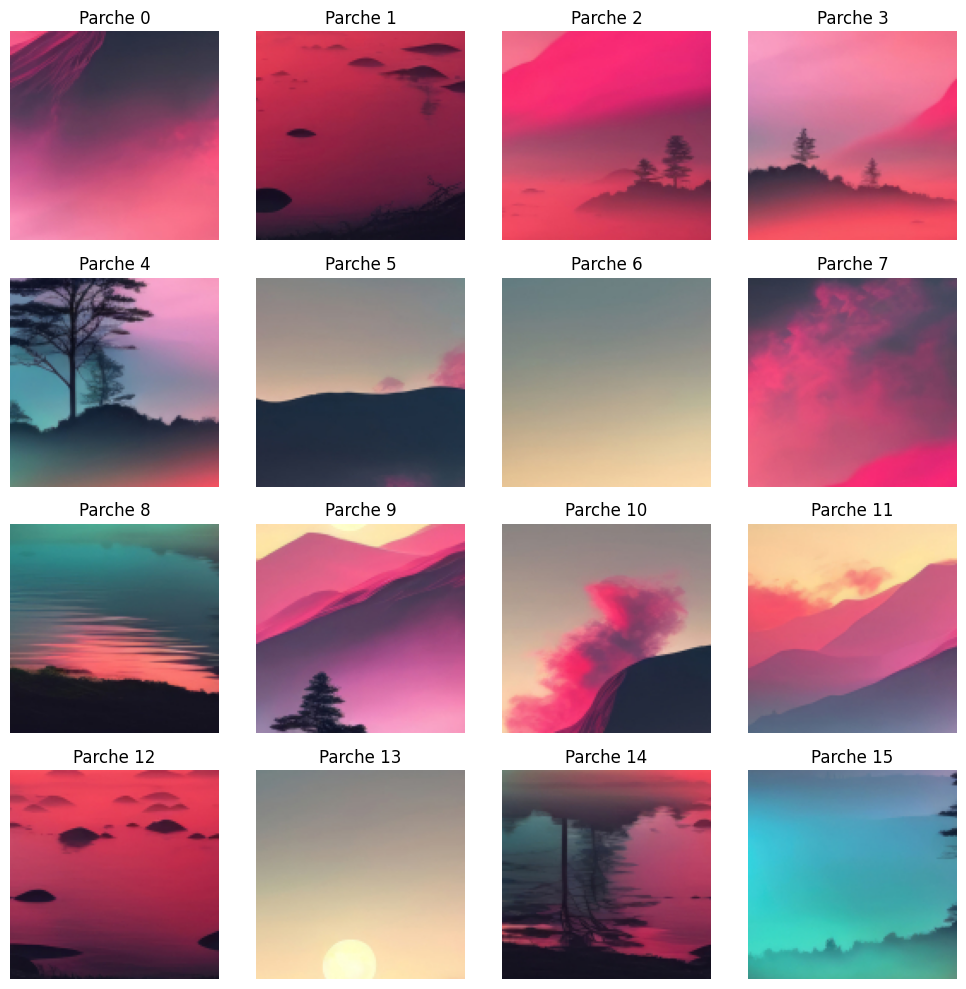

In [7]:
fig, axes = plt.subplots(R, C, figsize=(10, 10))

for i, ax in enumerate(axes.flat):
    ax.imshow(parches[i])
    ax.set_title(f"Parche {i}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [12]:
D_horiz, D_vert = calcular_matrices_compatibilidad_avanzada(
    parches,
    W_b=4,
    alfa=0.5
)

print("Dimensión D_horiz:", D_horiz.shape)
print("Dimensión D_vert:", D_vert.shape)

Dimensión D_horiz: (16, 16)
Dimensión D_vert: (16, 16)


In [16]:
# Simular el anclaje conocido usando el ground truth.
# Esto es solamente para evaluar el algoritmo.

id_ancla = ground_truth[0, 0]

anclaje_src = (id_ancla // C, id_ancla % C)
anclaje_tgt = (0, 0)

print("Parche ancla:", id_ancla)
print("Anclaje origen:", anclaje_src)
print("Anclaje destino:", anclaje_tgt)

grid_predicho = ensamblar_mosaico_greedy(
    D_horiz,
    D_vert,
    R,
    C,
    anclaje_src,
    anclaje_tgt
)

print("Grilla predicha:")
print(grid_predicho)

Parche ancla: 6
Anclaje origen: (np.int64(1), np.int64(2))
Anclaje destino: (0, 0)
Grilla predicha:
[[ 6 13 10 15]
 [11  9  0  8]
 [ 5  2  3 14]
 [ 7  1 12  4]]


In [14]:
anclaje_src = (0, 0)
anclaje_tgt = (0, 0)

grid_predicho = ensamblar_mosaico_greedy(
    D_horiz,
    D_vert,
    R,
    C,
    anclaje_src,
    anclaje_tgt
)

print("Grilla predicha:")
print(grid_predicho)

Grilla predicha:
[[ 0  7  6 13]
 [ 3  2 11  9]
 [12  1  5  8]
 [ 4 14 10 15]]


Exactitud: 50.0%
Parches correctos: 8 de 16


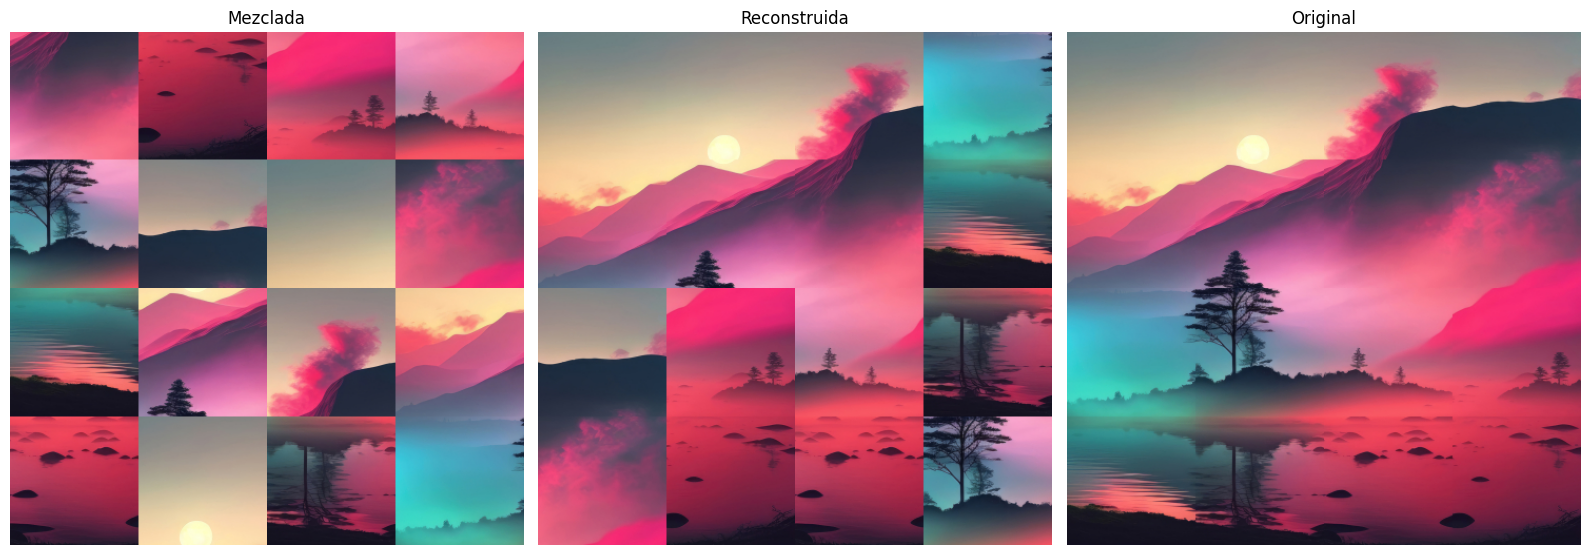

In [17]:
imagen_mezclada = reconstruir_imagen(
    parches,
    np.arange(R*C).reshape(R, C)
)

imagen_reconstruida = reconstruir_imagen(
    parches,
    grid_predicho
)

aciertos = grid_predicho == ground_truth
exactitud = np.mean(aciertos)

print(f"Exactitud: {exactitud:.1%}")
print(f"Parches correctos: {aciertos.sum()} de {R*C}")

fig, axes = plt.subplots(1, 3, figsize=(16, 6))

axes[0].imshow(imagen_mezclada)
axes[0].set_title("Mezclada")

axes[1].imshow(imagen_reconstruida)
axes[1].set_title("Reconstruida")

# Reconstrucción original para comparar
imagen_original = np.concatenate(
    [
        np.concatenate(
            [parches_originales[r*C+c] for c in range(C)],
            axis=1
        )
        for r in range(R)
    ],
    axis=0
)

axes[2].imshow(imagen_original)
axes[2].set_title("Original")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import importlib
import compatibilidad
import matriz_costos
import ensamblaje

# Recargar módulos para asegurarnos de utilizar el código actualizado
importlib.reload(compatibilidad)
importlib.reload(matriz_costos)
importlib.reload(ensamblaje)

# Usar exactamente el mismo anclaje
id_ancla = int(ground_truth[0, 0])
anclaje_src = (id_ancla // C, id_ancla % C)
anclaje_tgt = (0, 0)


def evaluar(D_h, D_v, nombre):
    prediccion = ensamblaje.ensamblar_mosaico_greedy(
        D_h, D_v, R, C,
        anclaje_src, anclaje_tgt
    )

    correctos = np.sum(prediccion == ground_truth)
    exactitud = correctos / (R * C) * 100

    print(f"\n{nombre}")
    print(prediccion)
    print(f"Exactitud: {exactitud:.1f}% ({correctos}/{R*C})")

    return exactitud


# A. Versión original
D_h_orig, D_v_orig = matriz_costos.calcular_matrices_compatibilidad2(
    parches, alfa=0.5
)

resultado_original = evaluar(
    D_h_orig, D_v_orig, "Compatibilidad original"
)


# B. Versión avanzada: probar diferentes anchos
resultados = []

for W_b in [2, 4, 8]:
    D_h, D_v = matriz_costos.calcular_matrices_compatibilidad_avanzada(
        parches, W_b=W_b, alfa=0.4
    )

    exactitud = evaluar(
        D_h, D_v, f"Avanzada W_b={W_b}, alfa=0.4"
    )

    resultados.append((W_b, 0.4, exactitud))


print("\nResumen de experimentos:")
print("Original:", resultado_original)

for W_b, alfa, exactitud in resultados:
    print(f"W_b={W_b}, alfa={alfa}: {exactitud:.1f}%")